# Ekman advection of single years

May Ekman advection of each single year 2023–2025, from the per-year pentad files (`ekman_mse.jl 2023 2025 peryear`), compared with the multi-year May climatology. Files are chosen in **Data** by `composite_file(stem, years)`: `y:y` for a single year, `2012:2025` for the climatology.

Libraries (`composites.jl`, `maps.jl`), loaded with Revise `includet`, and the kernel ("Julia") are as in `ekman_plots.ipynb`. Run the cells in order.

In [19]:
using Revise, Dates
includet("composites.jl") # reading composites, computing fields
includet("maps.jl")       # plotting

# display settings, which depend on the platform; change them here if figures look wrong or hang
plot_defaults!(; dpi=200) # inline figure size on screen (inches x dpi); fonts=[...]: font list
PythonPlot.svg(false)     # true: inline SVG, which scales to the pane (maps are rasterized, so it stays small)

false

## Data
May: the 6 pentads best aligned with May (pentads 25:30, May 1–30; year ignored in the dates) of each single year in `years1`, and of the climatology over `years`, in the region `lonlim`, `latlim`.

In [2]:
years = 2012:2025  # period of the climatology
years1 = 2023:2025 # single years
lonlim, latlim = (40, 110), (0, 25) # degrees: Indian Ocean; only this region is read
Ro_rad = 250e3 # m, curtail M by r = 1 - exp(-y^2/Ro_rad^2) near the equator (plotting only)
may = (Date(2001, 5, 1), Date(2001, 5, 31)) # 6 pentads best aligned with these dates

file_clim = composite_file("ekman_pentad_clim_oisst", years) # in ../out
file_year = Dict(y => composite_file("ekman_pentad_clim_oisst", y:y) for y in years1)
f_clim = ekman_fields(file_clim, may...; n=6, lonlim, latlim, Ro_rad)
f_year = Dict(y => ekman_fields(file_year[y], may...; n=6, lonlim, latlim, Ro_rad) for y in years1)
# May to June shift of each single year: periods (dates, number of pentads), as in ekman_plots.ipynb
shift = (may=(may, 6), mayjun=((Date(2001, 5, 20), Date(2001, 6, 10)), 4), jun=((Date(2001, 6, 1), Date(2001, 6, 30)), 6))
f_shift = Dict(y => map(((d, n),) -> ekman_fields(file_year[y], d...; n, lonlim, latlim, Ro_rad), shift) for y in years1) # f_shift[y].jun
advsum(f) = f.adv_o .+ f.adv_a # ocean + atmosphere Ekman advection, W m^-2
mday(w) = 86400 .* w           # m/s -> m/day (Ekman pumping)
f_clim.dimval, basename(file_clim), [basename(file_year[y]) for y in years1]

(Int32[25, 26, 27, 28, 29, 30], "ekman_pentad_clim_oisst_20120401-20250803.nc", ["ekman_pentad_clim_oisst_20230401-20230803.nc", "ekman_pentad_clim_oisst_20240401-20240803.nc", "ekman_pentad_clim_oisst_20250401-20250803.nc"])

## Ocean and atmosphere Ekman advection, their sum, and its anomaly
Rows: years. Columns: ocean and atmosphere Ekman advection of (moist) enthalpy, their sum, and the sum minus the climatology's.

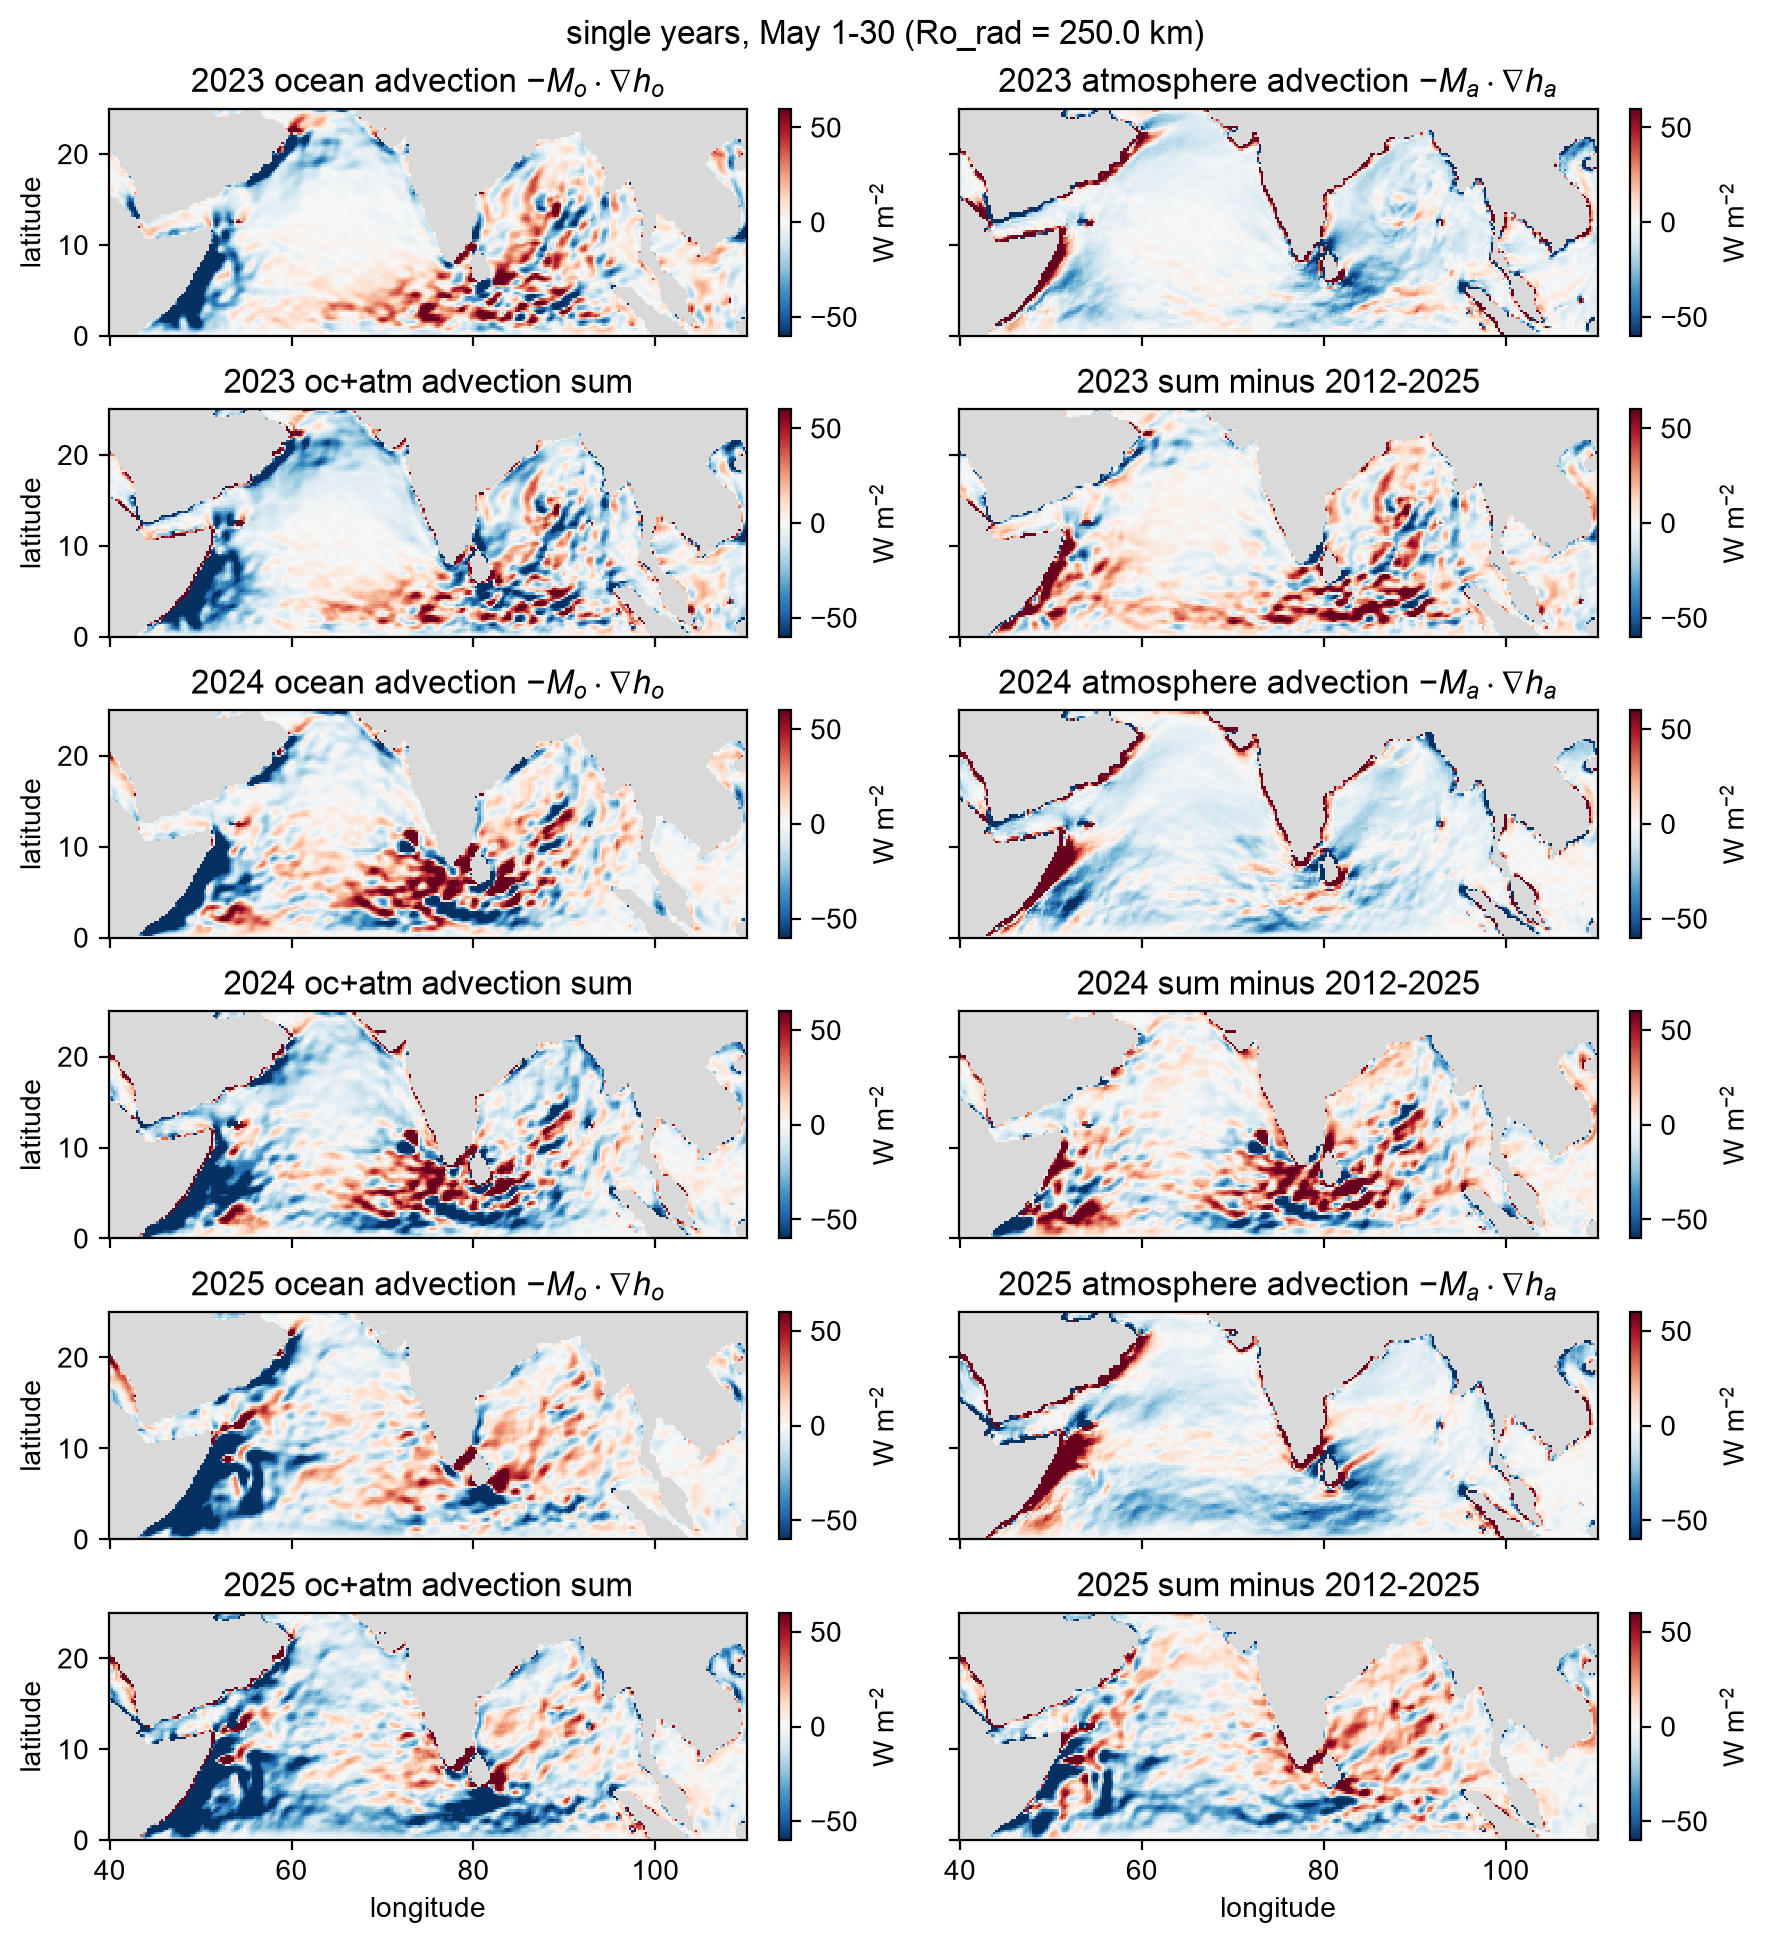

findfont: Failed to find font weight normal for Apple Chancery, now using 0.


In [3]:
Hlim, anomlim = 60, 60 # color limits: ±W m^-2 (advection), ±W m^-2 (anomaly of the sum)
fig_yr, axs_yr, meshes_yr, cbars_yr = plot_panels(f_clim, [
    p for y in years1 for p in (
        panel(f_year[y].adv_o, "$y ocean advection " * raw"$-M_o \cdot \nabla h_o$", flux_units; vmin=-Hlim, vmax=Hlim),
        panel(f_year[y].adv_a, "$y atmosphere advection " * raw"$-M_a \cdot \nabla h_a$", flux_units; vmin=-Hlim, vmax=Hlim),
        panel(advsum(f_year[y]), "$y oc+atm advection sum", flux_units; vmin=-Hlim, vmax=Hlim),
        panel(advsum(f_year[y]) .- advsum(f_clim), "$y sum minus $(first(years))-$(last(years))", flux_units;
              vmin=-anomlim, vmax=anomlim))];
    ncols=2, figsize=(22, 3.2length(years1)), ylim=latlim,
    suptitle="single years, $(period_label(f_clim.dimval)) (Ro_rad = $(Ro_rad/1e3) km)");
# fig_yr.savefig("ekman_adv_years_$(first(years1))-$(last(years1))_$(period_tag(f_clim.dimval)).png"; bbox_inches="tight")

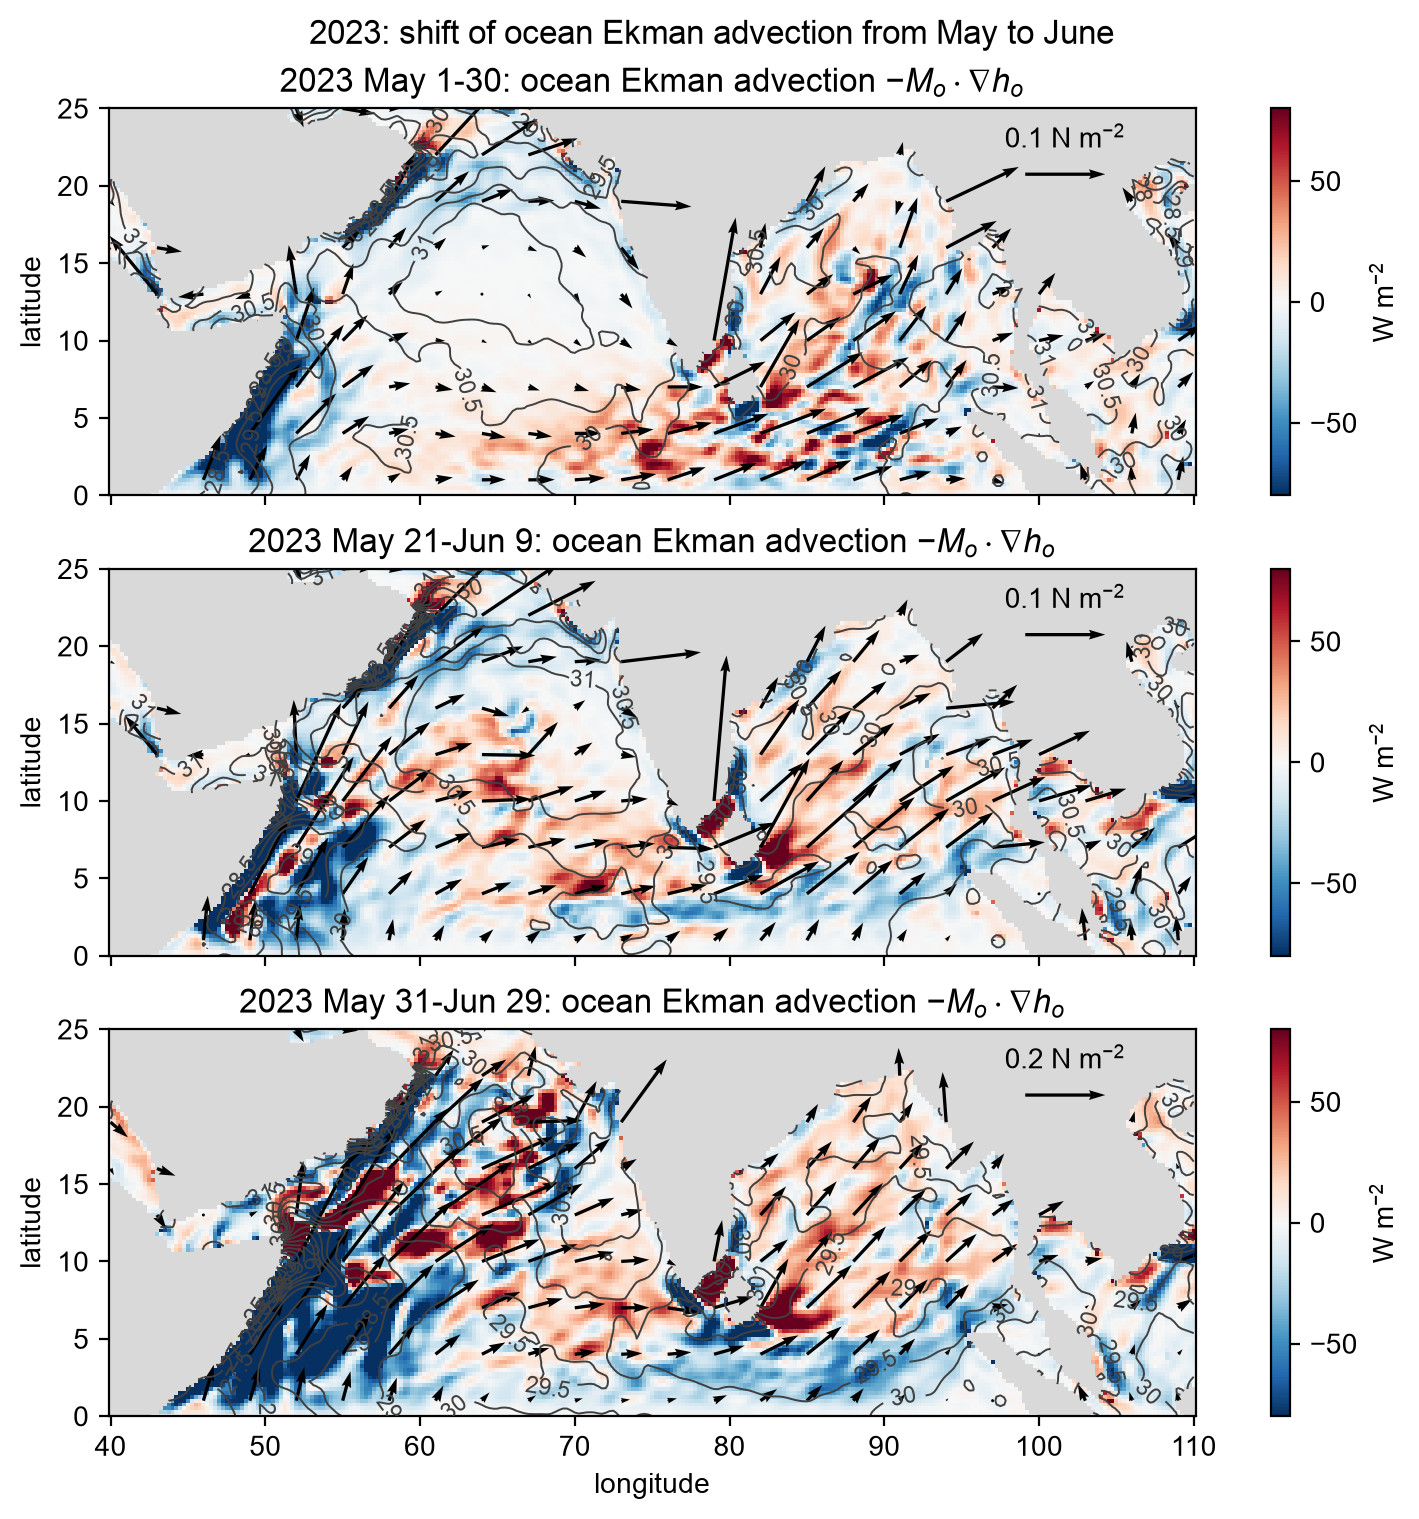

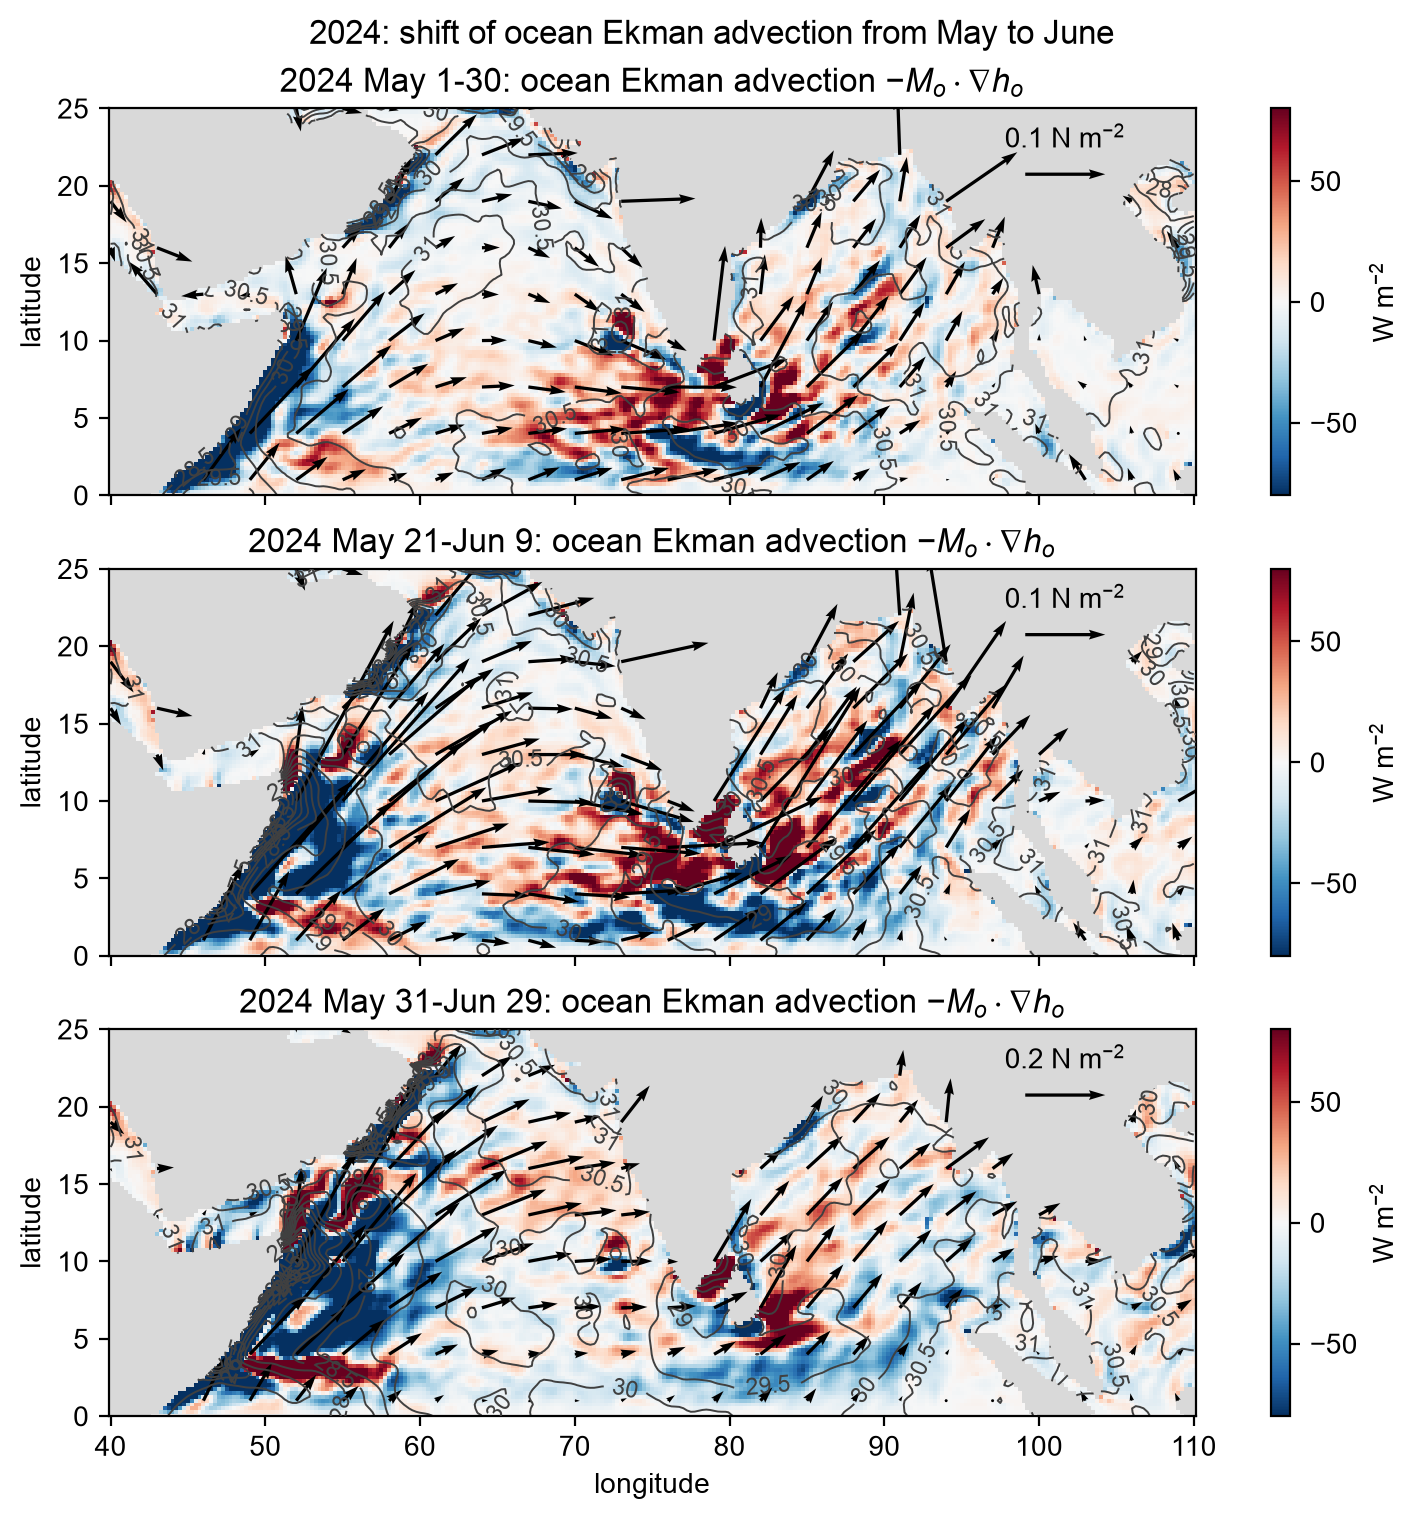

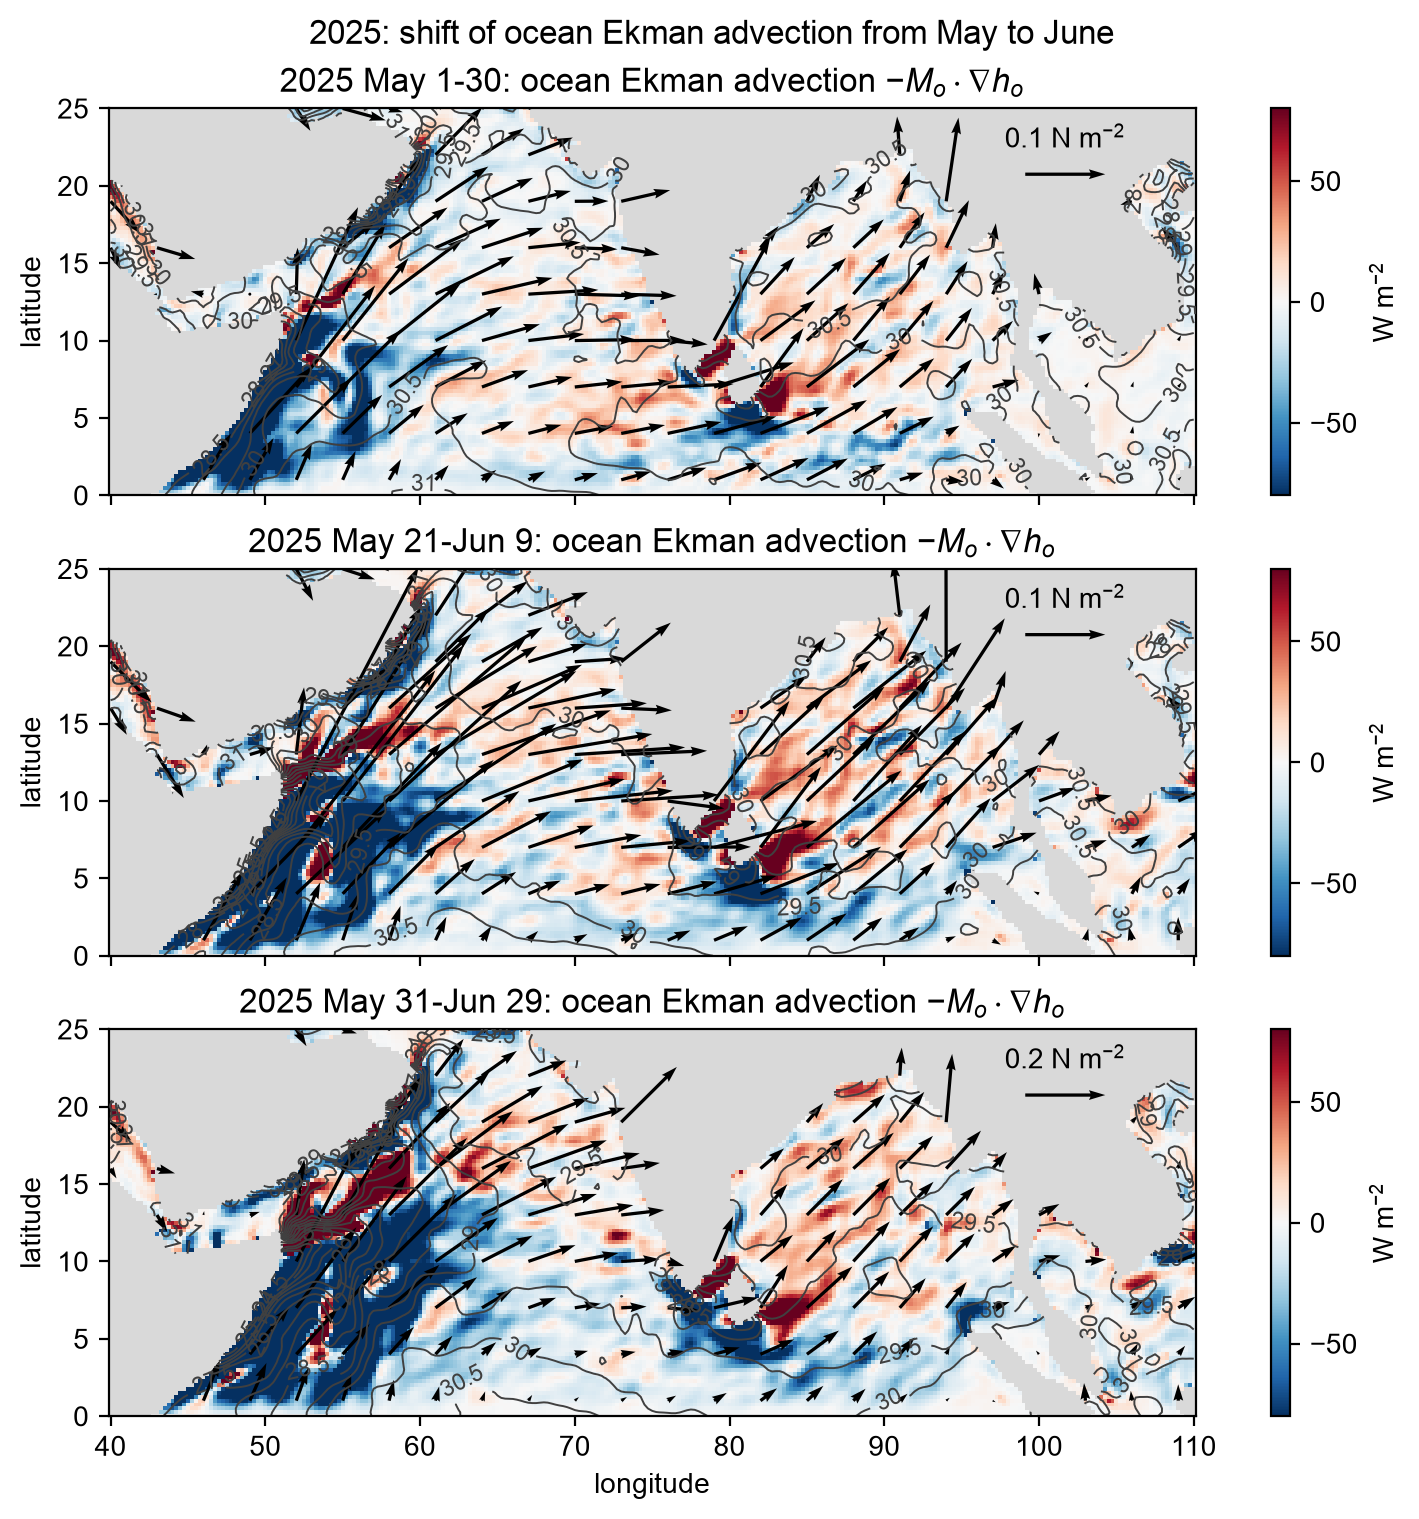

In [10]:
# May to June shift of ocean Ekman advection, one figure per year: colors -M_o⋅∇h_o, contours SST (°C), quivers wind stress
advlim = 80            # W m^-2: colors ±advlim
sst_levels = 24:0.5:31 # °C
ne = (0.88, 0.83)      # wind stress key position (axes fraction): northeast corner, over land
tau_scale = (may=0.25, mayjun=0.25, jun=0.5) # N m^-2 per inch: May arrows twice as long as June's
tau_key   = (may=0.1, mayjun=0.1, jun=0.2)   # N m^-2: key arrow length
fig_oshift = Dict(y => plot_panels(f_shift[y].may, [
    panel(f.adv_o, "$y " * period_label(f.dimval) * raw": ocean Ekman advection $-M_o \cdot \nabla h_o$", flux_units; vmin=-advlim, vmax=advlim,
          contours=sst_contours(f; levels=sst_levels),
          arrows=stress_arrows(f; scale=tau_scale[k], key=tau_key[k], keypos=ne, width=0.003))
    for (k, f) in pairs(f_shift[y])];
    ncols=1, ylim=latlim, suptitle="$y: shift of ocean Ekman advection from May to June") for y in years1);

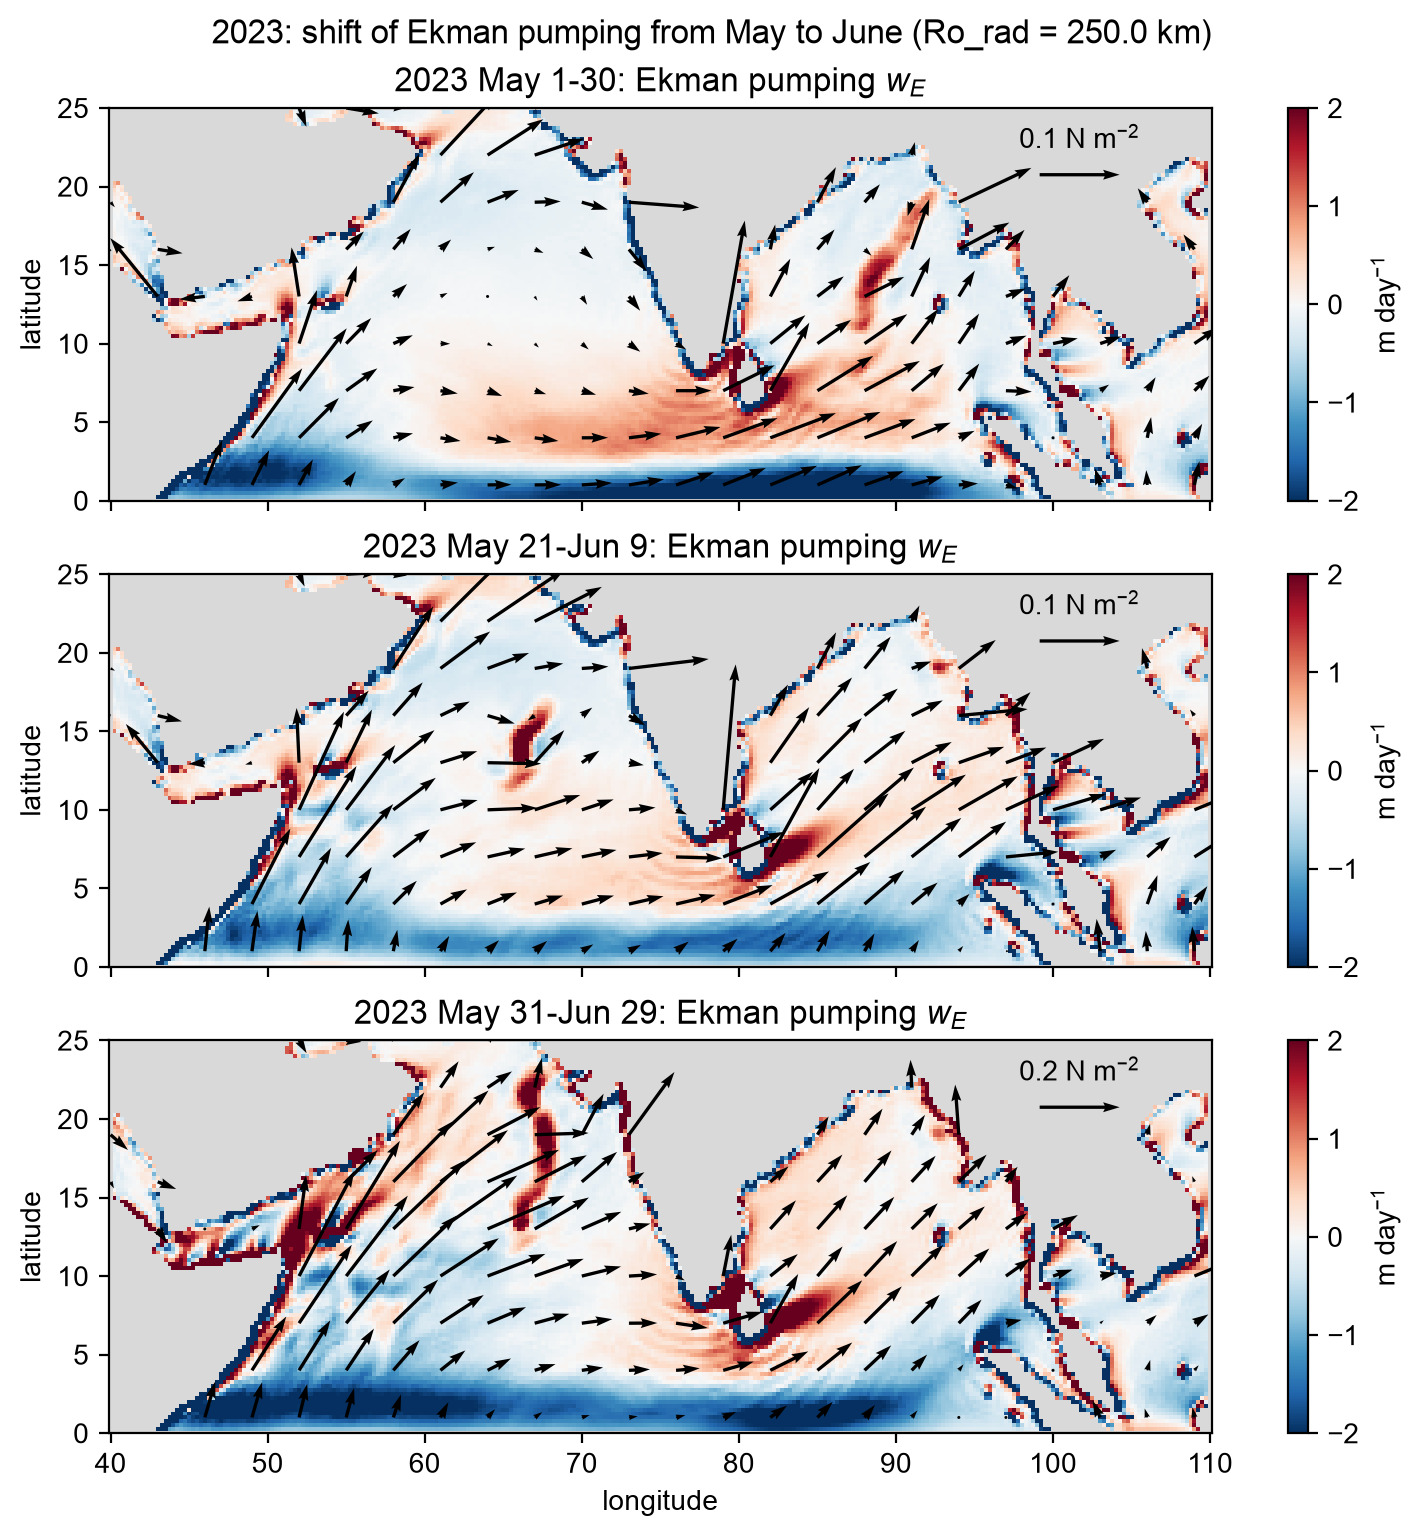

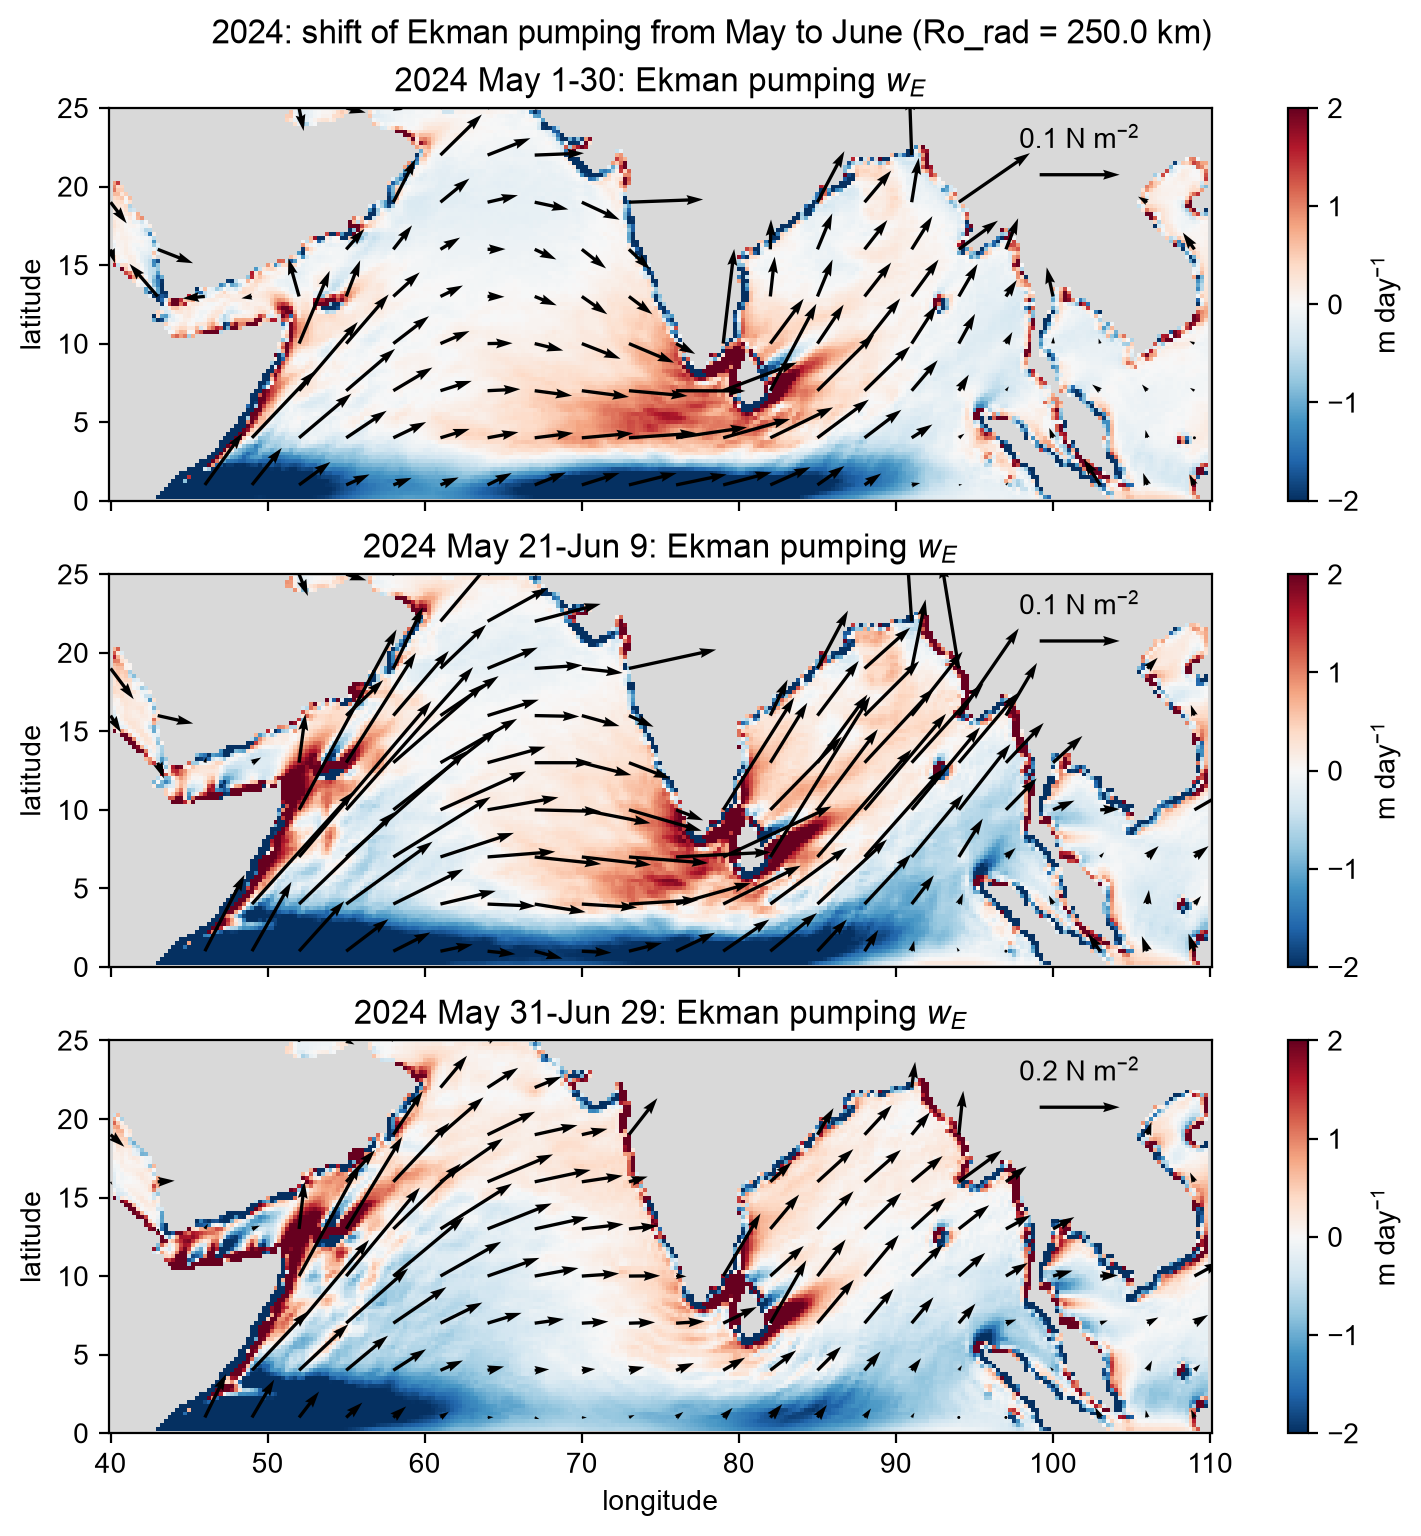

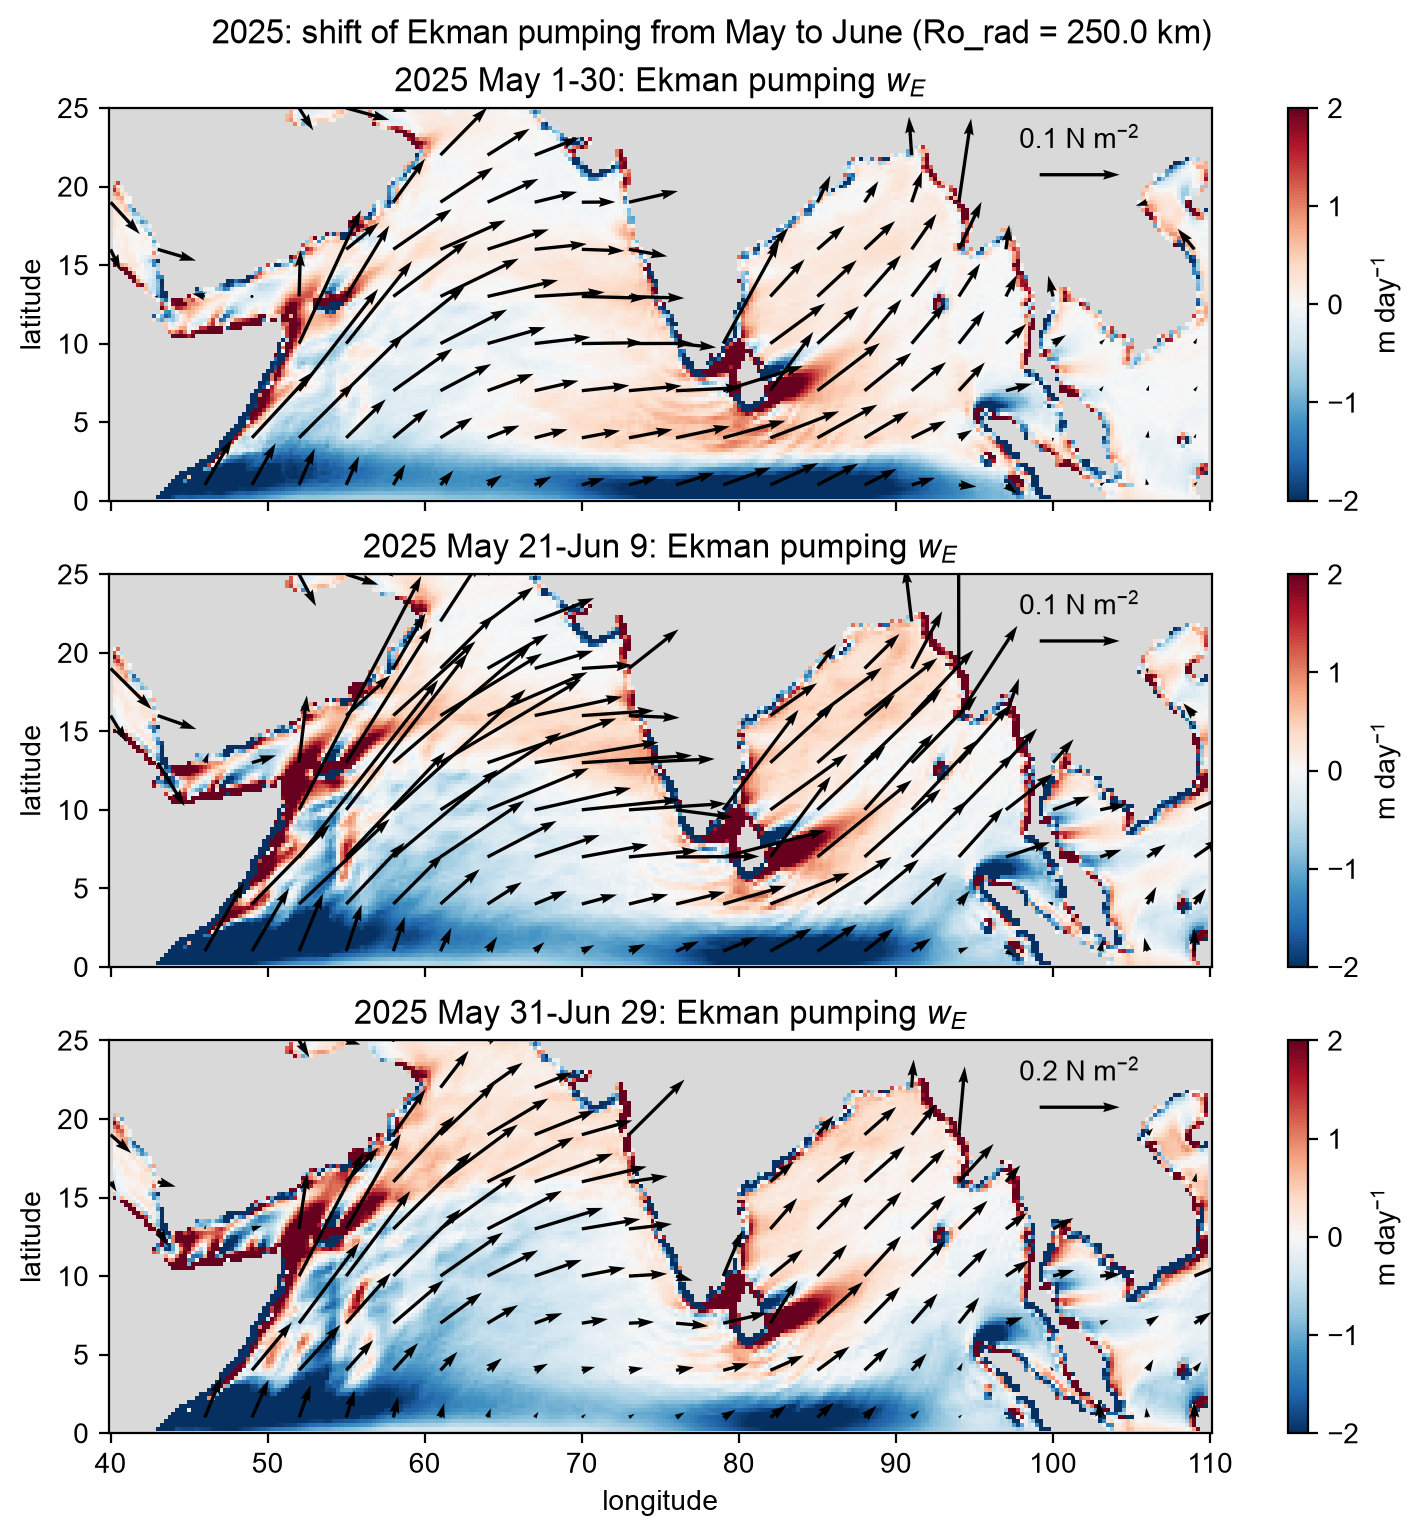

In [9]:
# May to June shift of Ekman pumping, one figure per year: w_E = ∇⋅M_o/ρ_o = curl(r τ/f)/ρ_o (upward > 0), m/day, with wind stress
wlim = 2              # m/day: colors ±wlim
fig_wshift = Dict(y => plot_panels(f_shift[y].may, [
    panel(mday(f.w_ek), "$y " * period_label(f.dimval) * raw": Ekman pumping $w_E$", w_units; vmin=-wlim, vmax=wlim,
          arrows=stress_arrows(f; scale=tau_scale[k], key=tau_key[k], keypos=ne, width=0.003))
    for (k, f) in pairs(f_shift[y])];
    ncols=1, ylim=latlim, suptitle="$y: shift of Ekman pumping from May to June (Ro_rad = $(Ro_rad/1e3) km)") for y in years1);

## Pentad time series of the Arabian Sea and the Bay of Bengal
Area-weighted means over the ocean points (`box_mean`, land masked) of the Arabian Sea (5–25 N, 50–80 E) and the Bay of Bengal (5–25 N, 80–100 E), for every pentad in the files (April–early August), of each single year in `years1` and of the climatology over `years`. The files hold pentad means, so these are pentad, not daily, series; points are at the middle day of each pentad.

In [22]:
# regions (ocean points only) and the fields of every pentad of each file (lon x lat x pentad)
regions = (AS=(name="Arabian Sea", lonlim=(50, 80), latlim=(5, 25)),
           BoB=(name="Bay of Bengal", lonlim=(80, 100), latlim=(5, 25)))
lonlim_ts, latlim_ts = (45, 105), (0, 30) # read a margin around the regions, so their edges have gradients
series_files = ["$(first(years))-$(last(years))" => file_clim; ["$y" => file_year[y] for y in years1]]
f_ts = [label => ekman_fields(read_group(file, :; lonlim=lonlim_ts, latlim=latlim_ts); Ro_rad) for (label, file) in series_files]
series(f, x, r) = box_mean(x, f.lon, f.lat, r.lonlim, r.latlim; f.land) # x: lon x lat x pentad -> pentads
pentad_day(p) = first(pentad_dates(p)) + Day(2) # middle day of pentad p (2001 calendar)
pentad_days(ps) = PythonPlot.PythonCall.pylist(pentad_day.(ps)) # as Python dates, for matplotlib
mmdd_ticks() = PythonPlot.matplotlib.dates.DateFormatter("%m.%d") # compact date tick labels, e.g. 05.15; a new one for each axis
style(k) = k == 1 ? (color="k", linewidth=2) : (color="C$(k-2)", linewidth=1) # climatology black, years in colors
[label => extrema(f.dimval) for (label, f) in f_ts]

4-element Vector{Pair{String, Tuple{Int32, Int32}}}:
 "2012-2025" => (19, 43)
      "2023" => (19, 43)
      "2024" => (19, 43)
      "2025" => (19, 43)

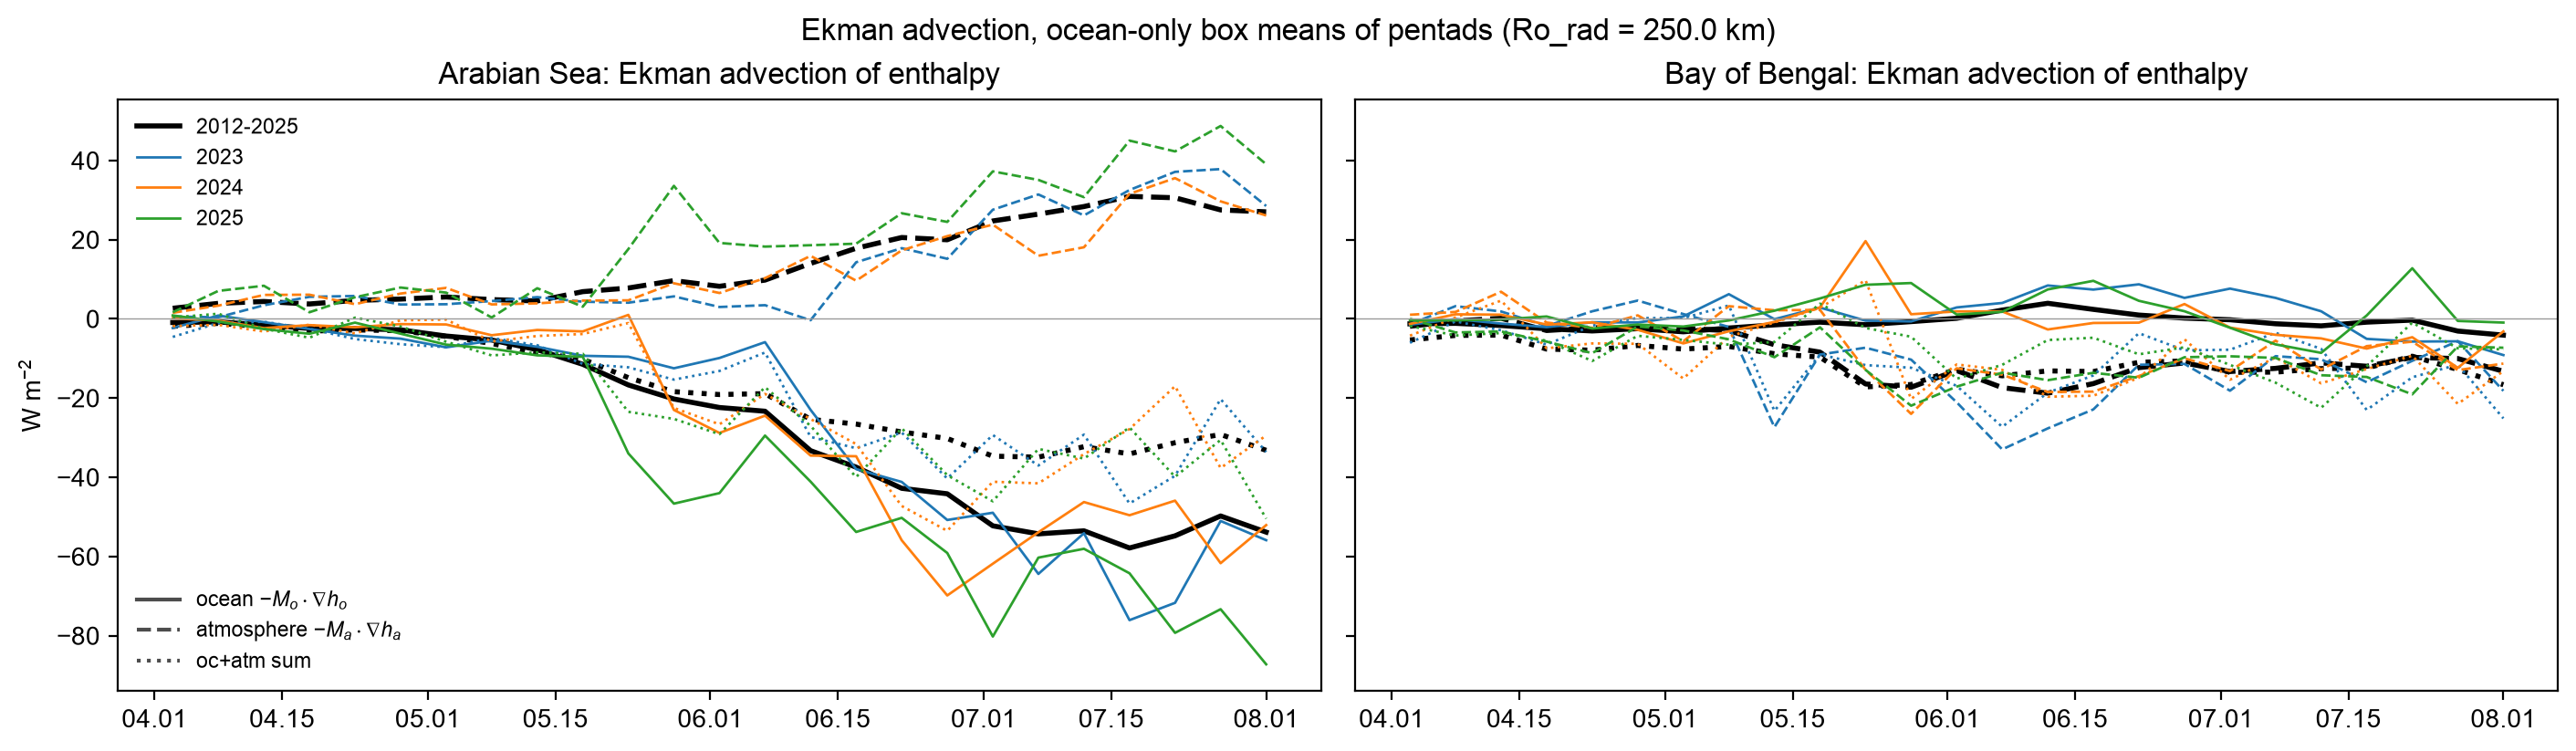

In [23]:
# Ekman advection time series: columns Arabian Sea (left), Bay of Bengal (right); ocean, atmosphere and their sum
# on the same axes in line styles; colors climatology (black) and years
advection = (("ocean " * raw"$-M_o \cdot \nabla h_o$", f -> f.adv_o, "-"),
             ("atmosphere " * raw"$-M_a \cdot \nabla h_a$", f -> f.adv_a, "--"),
             ("oc+atm sum", advsum, ":"))
pylist = PythonPlot.PythonCall.pylist
fig_tsadv, axs_tsadv = subplots(1, length(regions); figsize=(14, 4), sharex=true, sharey=true, layout="compressed", squeeze=false)
for (j, r) in enumerate(regions)
    ax = axs_tsadv[0, j-1]
    for (k, (label, f)) in enumerate(f_ts), (title, x, linestyle) in advection
        ax.plot(pentad_days(f.dimval), series(f, x(f), r); linestyle, style(k)...)
    end
    ax.axhline(0; color="0.6", linewidth=0.5)
    ax.set_title("$(r.name): Ekman advection of enthalpy")
    ax.xaxis.set_major_formatter(mmdd_ticks())
    j == 1 && ax.set_ylabel(flux_units)
end
# legends on the left panel: colors (climatology, years) and line styles (terms), from unplotted proxy lines
ax = axs_tsadv[0, 0]
legend_years = ax.legend(; handles=pylist([ax.plot([], []; label, style(k)...)[0] for (k, (label, f)) in enumerate(f_ts)]),
                         fontsize="small", loc="upper left")
ax.add_artist(legend_years)
ax.legend(; handles=pylist([ax.plot([], []; color="0.3", linestyle, label=title)[0] for (title, x, linestyle) in advection]),
          fontsize="small", loc="lower left")
fig_tsadv.suptitle("Ekman advection, ocean-only box means of pentads (Ro_rad = $(Ro_rad/1e3) km)");

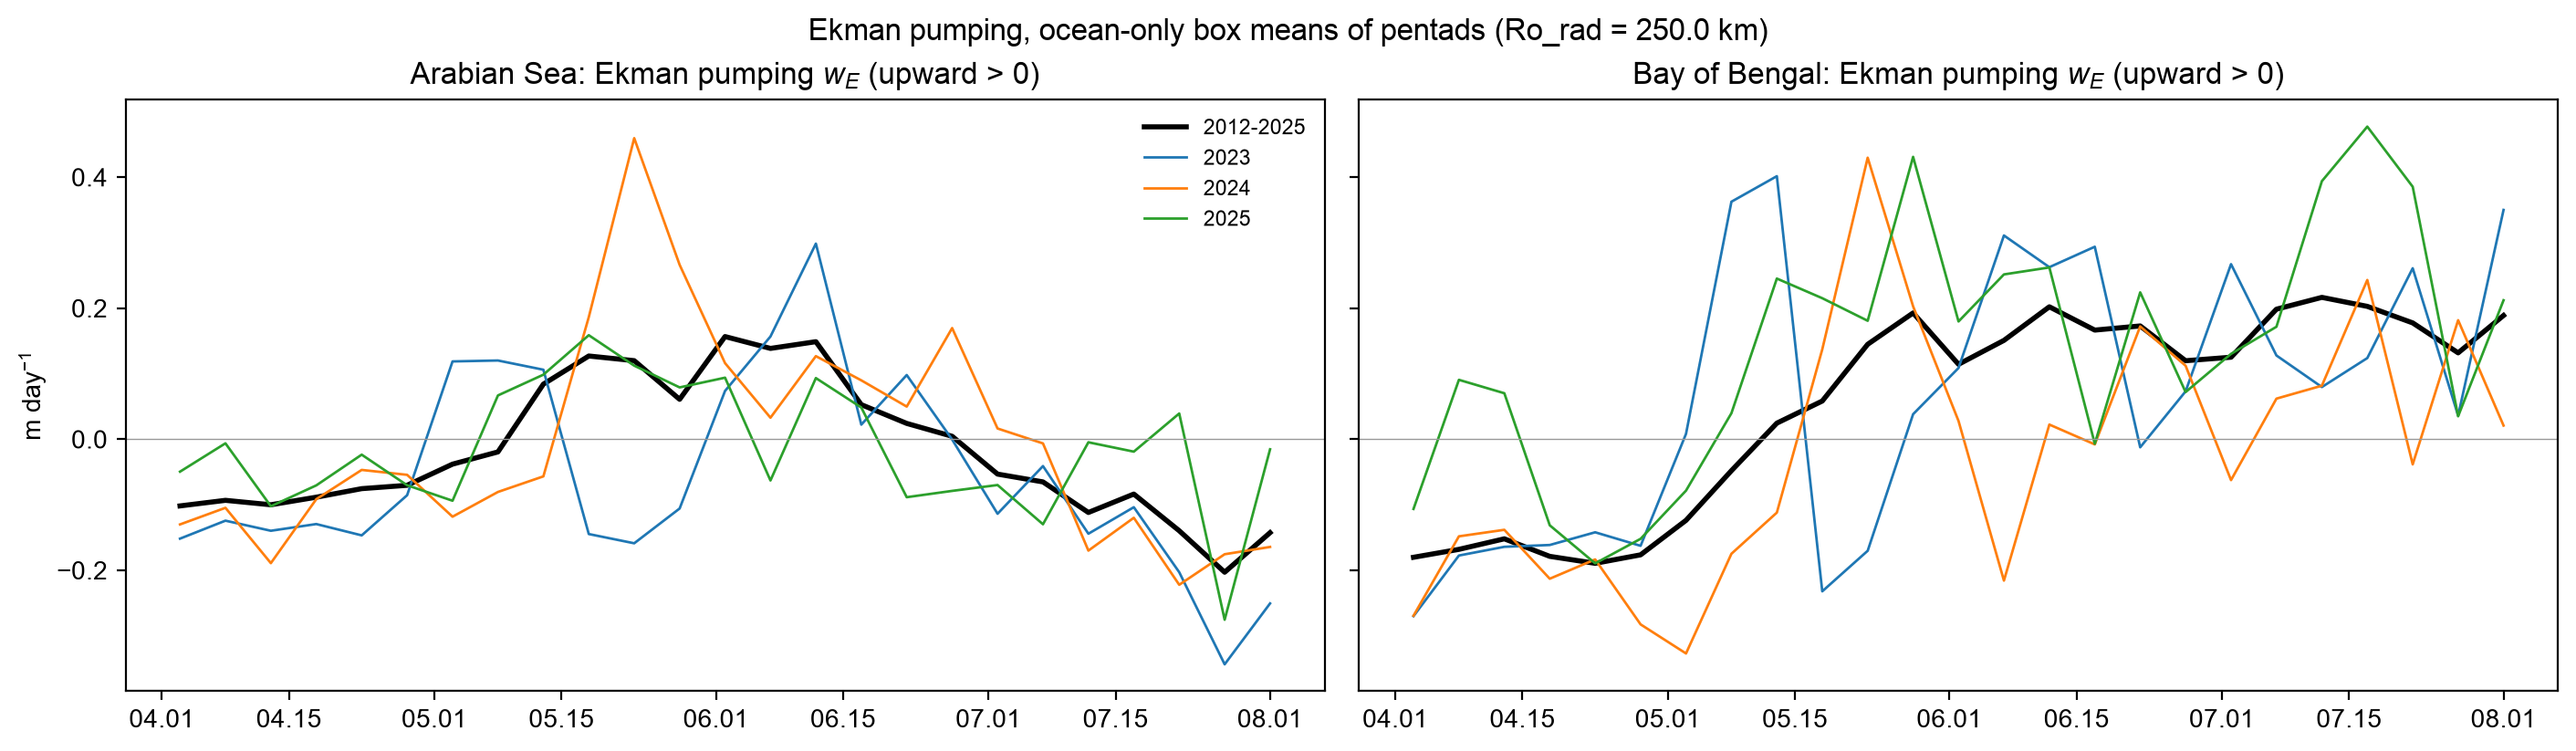

In [24]:
# Ekman pumping time series: columns Arabian Sea (left), Bay of Bengal (right); colors climatology (black) and years
fig_tsw, axs_tsw = subplots(1, length(regions); figsize=(14, 4), sharex=true, sharey=true, layout="compressed", squeeze=false)
for (j, r) in enumerate(regions)
    ax = axs_tsw[0, j-1]
    for (k, (label, f)) in enumerate(f_ts)
        ax.plot(pentad_days(f.dimval), series(f, mday(f.w_ek), r); label, style(k)...)
    end
    ax.axhline(0; color="0.6", linewidth=0.5)
    ax.set_title("$(r.name): Ekman pumping " * raw"$w_E$" * " (upward > 0)")
    ax.xaxis.set_major_formatter(mmdd_ticks())
    j == 1 && ax.set_ylabel(w_units)
end
axs_tsw[0, 0].legend(; fontsize="small")
fig_tsw.suptitle("Ekman pumping, ocean-only box means of pentads (Ro_rad = $(Ro_rad/1e3) km)");